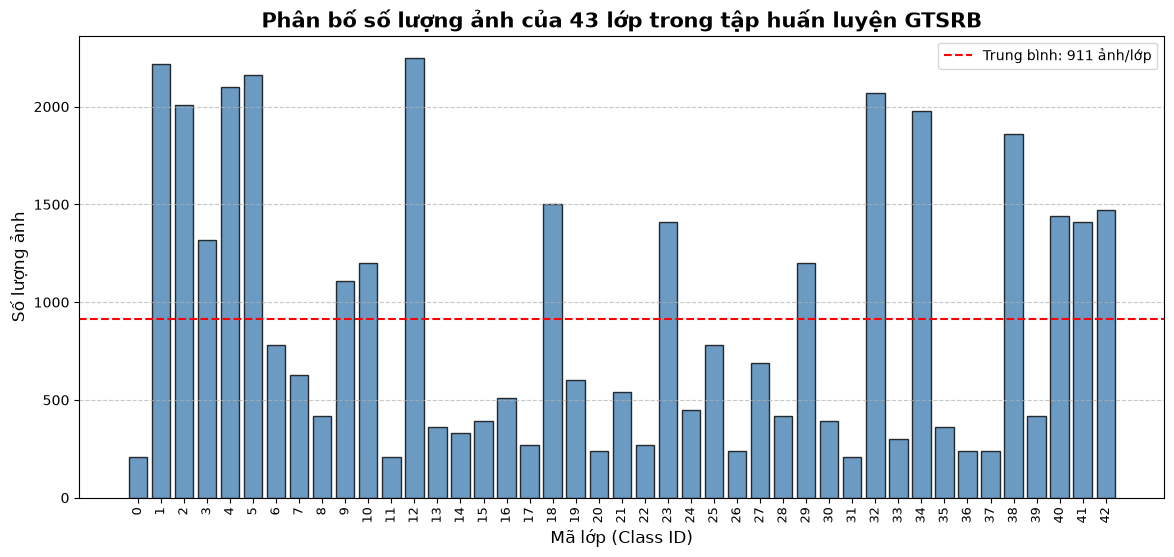

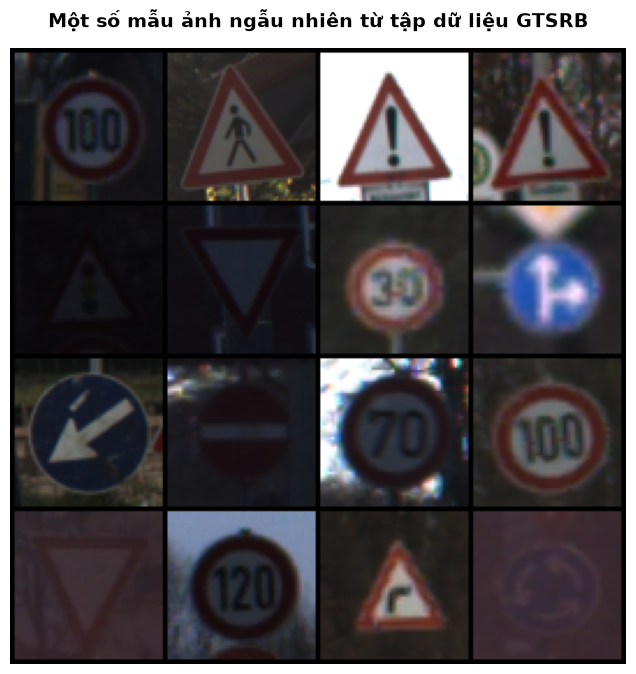

In [16]:
import os
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
from collections import Counter

train_dir = './archive/Train' 

# --- Hình 1: Biểu đồ phân bố ---
dataset_raw = datasets.ImageFolder(root=train_dir)
label_counts = Counter(dataset_raw.targets)

classes = list(label_counts.keys())
counts = list(label_counts.values())

plt.figure(figsize=(14, 6))
plt.bar(classes, counts, color='steelblue', edgecolor='black', alpha=0.8)
plt.title('Phân bố số lượng ảnh của 43 lớp trong tập huấn luyện GTSRB', fontsize=15, fontweight='bold')
plt.xlabel('Mã lớp (Class ID)', fontsize=12)
plt.ylabel('Số lượng ảnh', fontsize=12)
plt.xticks(range(43), rotation=90, fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.7)

mean_count = sum(counts) / len(counts)
plt.axhline(mean_count, color='red', linestyle='dashed', linewidth=1.5, label=f'Trung bình: {int(mean_count)} ảnh/lớp')
plt.legend()
plt.savefig('hinh1.png', bbox_inches='tight', dpi=300)
plt.show()
plt.close() 

# --- Hình 2: Lưới ảnh mẫu ngẫu nhiên ---
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset_transformed = datasets.ImageFolder(root=train_dir, transform=transform)
dataloader = torch.utils.data.DataLoader(dataset_transformed, batch_size=16, shuffle=True)
images, _ = next(iter(dataloader))

grid_img = torchvision.utils.make_grid(images, nrow=4, padding=2)

plt.figure(figsize=(8, 8))
plt.imshow(grid_img.permute(1, 2, 0))
plt.axis('off')
plt.title("Một số mẫu ảnh ngẫu nhiên từ tập dữ liệu GTSRB", fontsize=14, fontweight='bold', pad=15)
plt.savefig('hinh2.png', bbox_inches='tight', dpi=300)
plt.show()